In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [18]:
df = pd.read_csv('../data/raw/Telco-Churn.csv')


In [19]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
df.shape

(7043, 21)

In [21]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

Imbalanced dataset - consider stratified sampling or SMOTE for modeling

Churn = N0: 5174(73.5%)

Churn = Yes: 1869 (26.5%)


In [17]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7032.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2283.300441,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.771362,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,401.450000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3794.737500,NaN


In [58]:
# Convert 'TotalCharges' to numeric, forcing errors to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [23]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7032.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,NaN,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,2283.300441,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,2266.771362,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,18.800000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,401.450000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,1397.475000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,3794.737500,NaN


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# Identify rows with NaN in 'TotalCharges'
df[df['TotalCharges'].isna()]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [26]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [28]:
df[df['TotalCharges'].isna()]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [29]:
df['Churn'].value_counts(normalize=True)


Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

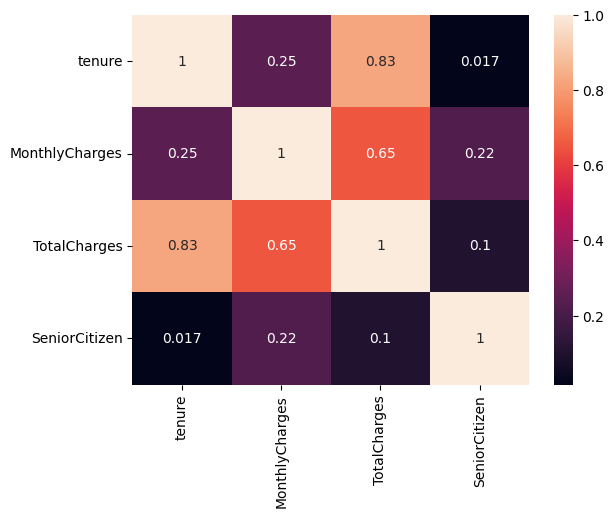

In [30]:
# Correlation heatmap (numeric columns)
sns.heatmap(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].corr(), annot=True)
plt.show()

In [ ]:
#  This suggests contract type could be useful for prediction, 
#  although it doesn’t prove that longer contracts cause lower churn.”
df.groupby('Contract')['Churn'].value_counts(normalize=True)


Contract        Churn
Month-to-month  No       0.572903
                Yes      0.427097
One year        No       0.887305
                Yes      0.112695
Two year        No       0.971681
                Yes      0.028319
Name: proportion, dtype: float64

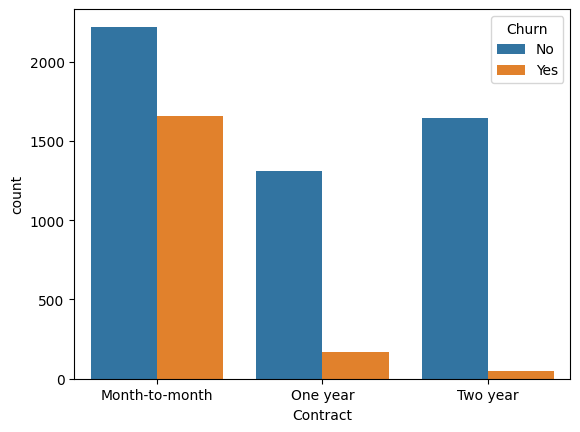

In [33]:
sns.countplot(data=df, x='Contract', hue='Churn')
plt.show()

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [35]:
# Binary Encoding
binary_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']

df[binary_cols] = df[binary_cols].replace({
    'Yes': 1,  'No': 0,
    'Male': 1, 'Female': 0
})

C:\Users\GPU2SHOP\AppData\Local\Temp\ipykernel_17844\1467452125.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[binary_cols] = df[binary_cols].replace({


In [36]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,5575-GNVDE,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,3668-QPYBK,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,7795-CFOCW,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [37]:
# One Hot Encoding
multi_cat_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

df = pd.get_dummies(df, columns=multi_cat_cols, drop_first=True)

In [38]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,0,0,1,0,1,0,1,29.85,29.85,0,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
1,5575-GNVDE,1,0,0,0,34,1,0,56.95,1889.50,0,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,True
2,3668-QPYBK,1,0,0,0,2,1,1,53.85,108.15,1,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
3,7795-CFOCW,1,0,0,0,45,0,0,42.30,1840.75,0,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False
4,9237-HQITU,0,0,0,0,2,1,1,70.70,151.65,1,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 32 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   customerID                             7043 non-null   object 
 1   gender                                 7043 non-null   int64  
 2   SeniorCitizen                          7043 non-null   int64  
 3   Partner                                7043 non-null   int64  
 4   Dependents                             7043 non-null   int64  
 5   tenure                                 7043 non-null   int64  
 6   PhoneService                           7043 non-null   int64  
 7   PaperlessBilling                       7043 non-null   int64  
 8   MonthlyCharges                         7043 non-null   float64
 9   TotalCharges                           7043 non-null   float64
 10  Churn                                  7043 non-null   int64  
 11  Mult

CLEANING

In [40]:
df = df.drop(['customerID'], axis=1)

In [41]:
bool_cols = df.select_dtypes(include=['bool']).columns
df[bool_cols] = df[bool_cols].astype(int) # Convert boolean columns to integers

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7043 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   int64  
 11  Mult

In [43]:
corr_matrix = df.corr(numeric_only=True)
churn_corr = corr_matrix['Churn'].sort_values(ascending=False)
print(churn_corr)

Churn                                    1.000000
InternetService_Fiber optic              0.308020
PaymentMethod_Electronic check           0.301919
MonthlyCharges                           0.193356
PaperlessBilling                         0.191825
SeniorCitizen                            0.150889
StreamingTV_Yes                          0.063228
StreamingMovies_Yes                      0.061382
MultipleLines_Yes                        0.040102
PhoneService                             0.011942
gender                                  -0.008612
MultipleLines_No phone service          -0.011942
DeviceProtection_Yes                    -0.066160
OnlineBackup_Yes                        -0.082255
PaymentMethod_Mailed check              -0.091683
PaymentMethod_Credit card (automatic)   -0.134302
Partner                                 -0.150448
Dependents                              -0.164221
TechSupport_Yes                         -0.164674
OnlineSecurity_Yes                      -0.171226


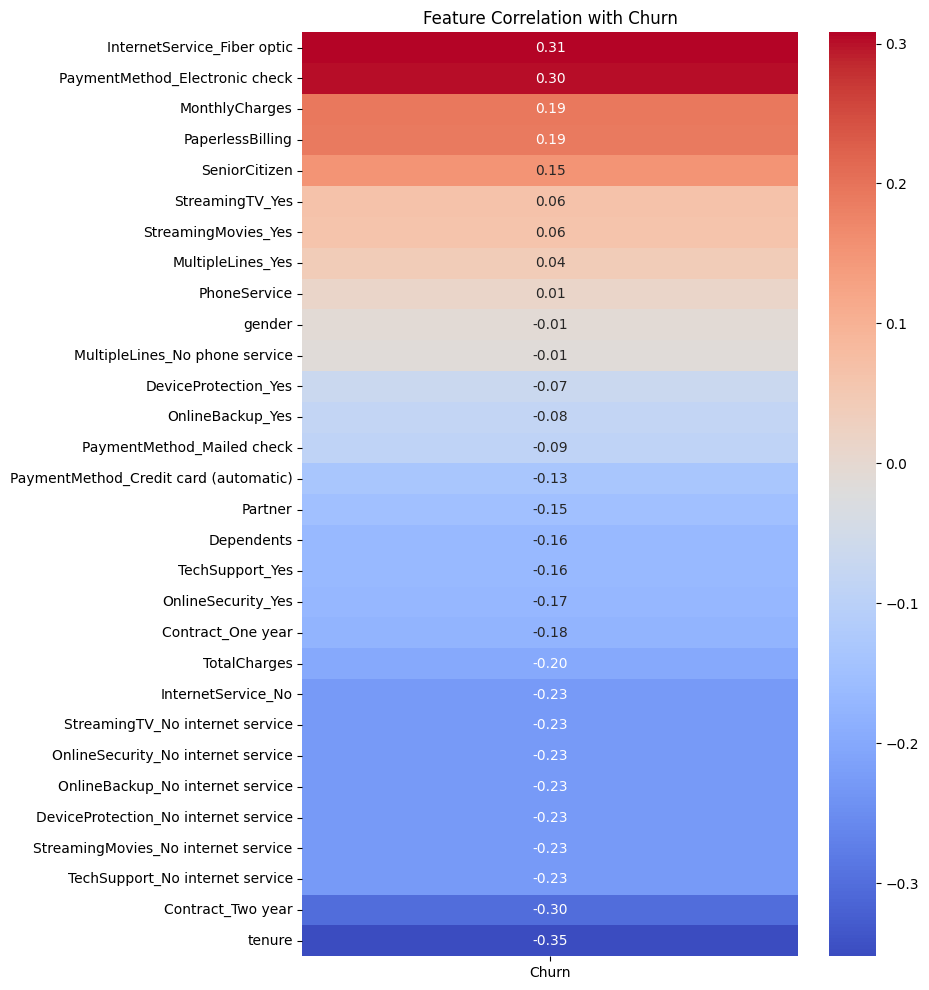

In [50]:
corr_matrix = df.corr(numeric_only=True)

#Correlation with churn
churn_corr = corr_matrix[['Churn']].drop('Churn').sort_values(by='Churn', ascending=False)

#Plot Heatmap for Churn correlations only
plt.figure(figsize=(8,12))
sns.heatmap(churn_corr, annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Feature Correlation with Churn')
plt.show()

# Churn Correlation Analysis Report

## Top Positive Correlations (Increase Churn Risk)

| Feature | Correlation | Interpretation |
|---------|-------------|----------------|
| **InternetService_Fiber optic** | 0.31 | Fiber optic customers churn more - possibly due to higher prices or service issues |
| **PaymentMethod_Electronic check** | 0.30 | Electronic check users are more likely to churn - may indicate less committed customers |
| **MonthlyCharges** | 0.19 | Higher monthly bills lead to more churn |
| **PaperlessBilling** | 0.19 | Paperless billing customers churn more - possibly less engaged with the service |
| **SeniorCitizen** | 0.15 | Senior citizens have slightly higher churn rates |

## Near-Zero Correlations (No Significant Impact)

| Feature | Correlation | Interpretation |
|---------|-------------|----------------|
| StreamingTV_Yes | 0.06 | Minimal impact |
| StreamingMovies_Yes | 0.06 | Minimal impact |
| MultipleLines_Yes | 0.04 | Minimal impact |
| PhoneService | 0.01 | No impact |
| gender | -0.01 | Gender has no effect on churn |

## Top Negative Correlations (Reduce Churn Risk)

| Feature | Correlation | Interpretation |
|---------|-------------|----------------|
| **tenure** | -0.35 | **Strongest predictor** - longer customers are much less likely to churn |
| **Contract_Two year** | -0.30 | Long-term contracts significantly reduce churn |
| **InternetService_No** | -0.23 | Customers without internet service churn less |
| **TotalCharges** | -0.20 | Higher lifetime value = lower churn (loyal customers) |
| **Contract_One year** | -0.18 | One-year contracts reduce churn |
| **OnlineSecurity_Yes** | -0.17 | Security add-on increases retention |
| **TechSupport_Yes** | -0.16 | Tech support add-on increases retention |
| **Dependents** | -0.16 | Customers with dependents are more stable |
| **Partner** | -0.15 | Partnered customers churn less |

---

## Key Business Insights

1. **Contract Type is Critical**: Month-to-month customers (the baseline) churn far more than those on 1-year (-0.18) or 2-year (-0.30) contracts. **Strategy**: Incentivize longer contracts.

2. **Tenure is the Strongest Predictor**: New customers are at highest risk. **Strategy**: Focus retention efforts on customers in their first year.

3. **Fiber Optic Paradox**: Despite being a premium service, fiber optic has the highest positive correlation with churn (0.31). **Investigate**: pricing, service quality, or competition in this segment.

4. **Payment Method Matters**: Electronic check users churn more (0.30). **Strategy**: Encourage automatic credit card or bank transfer payments.

5. **Value-Added Services Help Retention**: OnlineSecurity (-0.17) and TechSupport (-0.16) reduce churn. **Strategy**: Bundle these services or offer them at a discount.

6. **Price Sensitivity**: Higher MonthlyCharges correlate with churn (0.19), but higher TotalCharges correlate with retention (-0.20). This suggests customers who stay longer become less price-sensitive.

---

## Recommendations

1. **Early Intervention**: Target new customers (low tenure) with engagement programs
2. **Contract Incentives**: Offer discounts for 1-2 year contract commitments
3. **Fiber Optic Review**: Audit fiber optic service quality and pricing
4. **Payment Migration**: Encourage customers to switch from electronic check to automatic payments
5. **Bundle Services**: Promote security and tech support add-ons to increase stickiness

In [52]:
# MultiCollinearity Check


df["No_InternetService"] = (df['OnlineSecurity_No internet service'] |
                             df['OnlineBackup_No internet service'] |
                             df['DeviceProtection_No internet service'] |
                             df['TechSupport_No internet service'] |
                             df['StreamingTV_No internet service'] |
                             df['StreamingMovies_No internet service']).astype(int)

#drop the individual no internet service columns cuz they are now represented by the new column
drop_cols = [col for col in df.columns if "No internet service" in col]
df = df.drop(columns=drop_cols)

if 'MultipleLines_No phone service' in df.columns:
    df['No_phone_service'] = df['MultipleLines_No phone service'].astype(int)
    df = df.drop(columns=['MultipleLines_No phone service'])



In [ ]:
# Prepare X
X = df.drop(columns = 'Churn')
bool_cols = X.select_dtypes(include='bool').columns # Select boolean columns
X[bool_cols] = X[bool_cols].astype(int) # Convert boolean columns to integers

In [57]:
# Run VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor
import numpy as np

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by="VIF", ascending=False)

print(vif_data)

                                  feature          VIF
11                     InternetService_No          inf
23                     No_InternetService          inf
5                            PhoneService  1770.644580
7                          MonthlyCharges   865.062147
10            InternetService_Fiber optic   148.263380
24                       No_phone_service    60.867536
17                    StreamingMovies_Yes    24.110253
16                        StreamingTV_Yes    24.056827
8                            TotalCharges    10.793729
4                                  tenure     7.527280
9                       MultipleLines_Yes     7.273906
14                   DeviceProtection_Yes     6.922434
13                       OnlineBackup_Yes     6.782866
15                        TechSupport_Yes     6.467893
12                     OnlineSecurity_Yes     6.336249
19                      Contract_Two year     2.632246
21         PaymentMethod_Electronic check     1.976144
22        

c:\Users\GPU2SHOP\OneDrive\Desktop\Churn\venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [59]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,No_InternetService,No_phone_service
0,0,0,1,0,1,0,1,29.85,29.85,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1
1,1,0,0,0,34,1,0,56.95,1889.50,0,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,0
2,1,0,0,0,2,1,1,53.85,108.15,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0
3,1,0,0,0,45,0,0,42.30,1840.75,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,1
4,0,0,0,0,2,1,1,70.70,151.65,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0


# MACHINE LEARNING

In [60]:
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

class imbalance problelms
- 27% churners
- class weighting + threshold tuning is good enough

# In Churn Prediction, Recall is the most important (usually).

Recall = TP / (TP + FN)
"Of all customers who ACTUALLY left, how many did we catch?"
- care to catch every churners
- "Only flag customers I'm VERY sure will churn"


Business context Churn prediction is asymmetric in cost: 
- FN: Predict "not churn" but customer leaves -> miss the chance to intervene and keep them (did nth , customer gone)
- FP: Predict "churn" but customer statys -> might spend some rentention resources unnecessarily (like giving discount)

- Missing churners (FN) cost more than wrongly targeting a loyal customer 

# TRADE OFF

- if retentions are cheap -> proritize recall
- if expensive -> balance precision and recall using F1 score or precision-recall trade off

In [61]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from sklearn.metrics import classification_report
import pandas as pd
import time

In [62]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,No_InternetService,No_phone_service
0,0,0,1,0,1,0,1,29.85,29.85,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1
1,1,0,0,0,34,1,0,56.95,1889.50,0,0,0,0,1,0,1,0,0,0,1,0,0,0,1,0,0
2,1,0,0,0,2,1,1,53.85,108.15,1,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0
3,1,0,0,0,45,0,0,42.30,1840.75,0,0,0,0,1,0,1,1,0,0,1,0,0,0,0,0,1
4,0,0,0,0,2,1,1,70.70,151.65,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 26 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7043 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_Yes                      7043 non-null   int64  
 11  Inte

In [64]:
df.describe(include='all')

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,No_InternetService,No_phone_service
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.504756,0.162147,0.483033,0.299588,32.371149,0.903166,0.592219,64.761692,2279.734304,0.265370,0.421837,0.439585,0.216669,0.286668,0.344881,0.343888,0.290217,0.384353,0.387903,0.209144,0.240664,0.216101,0.335794,0.228880,0.216669,0.096834
std,0.500013,0.368612,0.499748,0.458110,24.559481,0.295752,0.491457,30.090047,2266.794470,0.441561,0.493888,0.496372,0.412004,0.452237,0.475363,0.475038,0.453895,0.486477,0.487307,0.406726,0.427517,0.411613,0.472301,0.420141,0.412004,0.295752
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,35.500000,398.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,70.350000,1394.550000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,89.850000,3786.600000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,118.750000,8684.800000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [67]:
X = df.drop(columns = ['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) #stratify because of class imbalance
THRESHOLD = 0.3 #lower for recall (Flag anyone with even small chance of churning)

## RANDOMFOREST CLASSIFIER

In [111]:
rf = RandomForestClassifier(
    n_estimators=300, 
    random_state=42, 
    class_weight='balanced',
    n_jobs=-1)

rf.fit(X_train, y_train)

proba = rf.predict_proba(X_test)[:, 1] #get for churn probablity column
y_pred = (proba >= THRESHOLD).astype(int)  #higher than 0.3 ? turn to [0,1] label

print(classification_report(y_test, y_pred, digits = 3))

              precision    recall  f1-score   support

           0      0.882     0.759     0.816      1035
           1      0.519     0.719     0.603       374

    accuracy                          0.749      1409
   macro avg      0.701     0.739     0.710      1409
weighted avg      0.786     0.749     0.760      1409



In [112]:
from sklearn.metrics import precision_score, recall_score, f1_score

proba = rf.predict_proba(X_test)[:, 1] #get for churn probablity column
print("Threshold tuning for RandomForest")

print(f"{'Thresh':<8}{'Precision':<8}{' Recall':<8}{'F1-Score':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    y_pred = (proba >= thresh).astype(int)
    precision = precision_score(y_test, y_pred,pos_label=1)
    recall = recall_score(y_test, y_pred,pos_label=1)
    f1 = f1_score(y_test, y_pred,pos_label=1)
    print(f"{thresh:<8}{precision:<8.3f}{recall:<8.3f}{f1:<8.3f}")

Threshold tuning for RandomForest
Thresh  Precision Recall F1-Score
0.25    0.516   0.799   0.627   
0.3     0.519   0.719   0.603   
0.35    0.546   0.666   0.600   
0.4     0.571   0.620   0.595   
0.45    0.605   0.553   0.578   
0.5     0.618   0.484   0.543   


0.25 
- Highest Recall
- Catches 80% of churners
- Half are false alarms (Precision)


0.25 gives the best performance


- Your budget situation         →  Best threshold
- Unlimited retention budget    →  0.25 (max recall)
- Normal budget                 →  0.30 (balanced) 
- Tight budget                  →  0.40 (compromise)
- Very limited budget           →  0.50 (high precision)

## LightGBM CLASSIFIER

In [113]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

#Training Timer
start_train = time.time()
lgbm.fit(X_train, y_train)
end_train = time.time()
train_time = end_train - start_train
print(f"LightGBM Training Time: {train_time:.2f} seconds")

#Prediction Timer
start_pred = time.time()
proba = lgbm.predict_proba(X_test)[:, 1] #get for churn probablity column
y_pred = (proba >= THRESHOLD).astype(int)  #higher than 0.3 ? turn to [0,1] label
pred_time = time.time() - start_pred
print(f"LightGBM Prediction Time: {pred_time:.4f} seconds")

print(classification_report(y_test, y_pred, digits = 3))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000808 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 627
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
LightGBM Training Time: 0.41 seconds
LightGBM Prediction Time: 0.0053 seconds
              precision    recall  f1-score   support

           0      0.914     0.695     0.789      1035
           1      0.492     0.818     0.614       374

    accuracy                          0.727      1409
   macro avg      0.703     0.756     0.702      1409
weighted avg      

Catch 82% of actual churners with LightGMB(improvement from RM)

The cost is small drop in precision(53 to 49), meaning more loyal customers will be flaggest as churn risks but if rentention offers are low-cost , it's fine

In [114]:
proba = lgbm.predict_proba(X_test)[:, 1] #get for churn probablity column
print("Threshold tuning for LightGBM")
print(f"{'Thresh':<8}{'Precision':<8}{' Recall':<8}{'F1-Score':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    y_pred = (proba >= thresh).astype(int)
    precision = precision_score(y_test, y_pred,pos_label=1)
    recall = recall_score(y_test, y_pred,pos_label=1)
    f1 = f1_score(y_test, y_pred,pos_label=1)
    print(f"{thresh:<8}{precision:<8.3f}{recall:<8.3f}{f1:<8.3f}")

Threshold tuning for LightGBM
Thresh  Precision Recall F1-Score
0.25    0.477   0.840   0.609   
0.3     0.492   0.818   0.614   
0.35    0.509   0.797   0.621   
0.4     0.529   0.775   0.629   
0.45    0.550   0.746   0.633   
0.5     0.558   0.709   0.624   


0.25 
- Highest Recall
- Catches 84% of churners
- 47% false alarms
- Use if we can afford many rentention offers

0.40
- Catch 77% of churners
- Reasonable precision score
- Balance

0.25 is perfect . low false alarms and high catch rate

## XGBoost CLASSIFIER

In [115]:
from xgboost import XGBClassifier

#Calculate scale_pos_weight for imbalanced classes
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss'
)

#Training Timer
start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"XGBoost Training Time: {train_time:.2f} seconds")

#Prediction Timer
start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1] #get for churn probablity column
y_pred = (proba >= THRESHOLD).astype(int)  #higher than 0.3 ? turn to [0,1] label
pred_time = time.time() - start_pred
print(f"XGBoost Prediction Time: {pred_time:.4f} seconds")

print(classification_report(y_test, y_pred, digits = 3))

XGBoost Training Time: 0.36 seconds
XGBoost Prediction Time: 0.0056 seconds
              precision    recall  f1-score   support

           0      0.913     0.681     0.780      1035
           1      0.482     0.821     0.607       374

    accuracy                          0.718      1409
   macro avg      0.698     0.751     0.694      1409
weighted avg      0.799     0.718     0.734      1409



In [116]:
proba = xgb.predict_proba(X_test)[:, 1] #get for churn probablity column
print("Threshold tuning for XGBoost")
print(f"{'Thresh':<8}{'Precision':<8}{' Recall':<8}{'F1-Score':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    y_pred = (proba >= thresh).astype(int)
    precision = precision_score(y_test, y_pred,pos_label=1)
    recall = recall_score(y_test, y_pred,pos_label=1)
    f1 = f1_score(y_test, y_pred,pos_label=1)
    print(f"{thresh:<8}{precision:<8.3f}{recall:<8.3f}{f1:<8.3f}")

Threshold tuning for XGBoost
Thresh  Precision Recall F1-Score
0.25    0.465   0.842   0.599   
0.3     0.482   0.821   0.607   
0.35    0.500   0.794   0.614   
0.4     0.519   0.765   0.618   
0.45    0.528   0.722   0.610   
0.5     0.546   0.687   0.608   


BEST THRESHOLD
- 0.25 with 84% recall (same as LightGBM)

### BASELINE COMPARSION XGBoost vs LightGBM

- Recall at thresh 0.25 - XGBoost (84.2) - LightGBM (84.0) ---> Almost identical XGBoost wins
- F1-Score at thresh 0.25 - XGBoost (59.9) - LightGBM (60.9) ---> LightGBM wins
- Precision - LightGBM wins every threshold
- Training Speed- LightGM 0.41s is 1.13 times slower than XGBoost 0.36s -- XGBoost wins

**Why LightGBM?**
- Same recall (catches same number of churners)
- Better precision = fewer wasted retention offers
- Better F1 = better overall balance
- Speed difference (0.05s) is meaningless in practice

The 0.2% recall advantage of XGBoost equals ~1 extra churner caught out of 374. Not worth sacrificing precision and F1 for.

## Hyperparameter Tuning with Optuna

In [120]:
THRESHOLD = 0.25

In [ ]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split

def objective(trail):
    params={
        'n_estimators': trail.suggest_int('n_estimators', 300, 800),
        'learning_rate': trail.suggest_float('learning_rate', 0.01, 0.2),
        'max_depth': trail.suggest_int('max_depth', 3, 10),
        'subsample': trail.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trail.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trail.suggest_int('min_child_weight', 1, 10),
        'gamma': trail.suggest_float('gamma', 0, 5),
        'reg_alpha': trail.suggest_float('reg_alpha', 0, 5),
        'reg_lambda': trail.suggest_float('reg_lambda', 0, 5),
        'scale_pos_weight': (y_train == 0).sum() / (y_train == 1).sum(),
        'random_state': 42,
        'n_jobs': -1,
        'eval_metric': 'logloss'
    }

    model = XGBClassifier(**params)
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)
    return recall_score(y_test, y_pred, pos_label=1)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)

print("Best Params:", study.best_params)
print("Best Recall:", study.best_value)

[I 2025-12-10 12:04:51,985] A new study created in memory with name: no-name-7c27fd34-ed97-4546-9670-ddd3299b981d
[I 2025-12-10 12:04:52,165] Trial 0 finished with value: 0.9278074866310161 and parameters: {'n_estimators': 598, 'learning_rate': 0.17178812536595947, 'max_depth': 5, 'subsample': 0.7885862538269788, 'colsample_bytree': 0.768153079872445, 'min_child_weight': 7, 'gamma': 3.381982239169803, 'reg_alpha': 1.7492366819698668, 'reg_lambda': 1.6501876947587375}. Best is trial 0 with value: 0.9278074866310161.
[I 2025-12-10 12:04:52,345] Trial 1 finished with value: 0.9197860962566845 and parameters: {'n_estimators': 683, 'learning_rate': 0.14393470136289044, 'max_depth': 5, 'subsample': 0.7875026498923516, 'colsample_bytree': 0.9830885766089499, 'min_child_weight': 9, 'gamma': 3.9424958471752363, 'reg_alpha': 1.6177285039549956, 'reg_lambda': 1.0284075064012392}. Best is trial 0 with value: 0.9278074866310161.
[I 2025-12-10 12:04:52,554] Trial 2 finished with value: 0.92780748663

Best Params: {'n_estimators': 301, 'learning_rate': 0.12116916309903428, 'max_depth': 9, 'subsample': 0.997637352602312, 'colsample_bytree': 0.7923767039938633, 'min_child_weight': 9, 'gamma': 4.367151459012173, 'reg_alpha': 0.9596254177102923, 'reg_lambda': 1.3640804360067864}
Best Recall: 0.9411764705882353


In [122]:
# Calcualte scale_pos_weight for imbalanced classes
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

best_params = study.best_params
best_params.update({"random_state":42, "n_jobs":-1, "scale_pos_weight":scale_pos_weight, "eval_metric":"logloss"})

xgb = XGBClassifier(**best_params)

start_train = time.time()
xgb.fit(X_train, y_train)
end_train = time.time()
train_time = end_train - start_train
print(f"Optimized XGBoost Training Time: {train_time:.2f} seconds")

start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1] #get for churn probablity column
y_pred = (proba >= THRESHOLD).astype(int)  #higher than
pred_time = time.time() - start_pred
print(f"Optimized XGBoost Prediction Time: {pred_time:.4f} seconds")

print(classification_report(y_test, y_pred, digits = 3))

Optimized XGBoost Training Time: 0.10 seconds
Optimized XGBoost Prediction Time: 0.0040 seconds
              precision    recall  f1-score   support

           0      0.961     0.529     0.682      1035
           1      0.419     0.941     0.580       374

    accuracy                          0.638      1409
   macro avg      0.690     0.735     0.631      1409
weighted avg      0.817     0.638     0.655      1409



In [ ]:
#Optuna for LightGBM
import optuna
from lightgbm import LGBMClassifier

def objective_lgbm(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 800),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
        'num_leaves': trial.suggest_int('num_leaves', 20, 150),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0, 5),
        'reg_lambda': trial.suggest_float('reg_lambda', 0, 5),
        'class_weight': 'balanced',
        'random_state': 42,
        'n_jobs': -1
    }

    model = LGBMClassifier(**params)
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)
    return recall_score(y_test, y_pred, pos_label=1)
study_lgbm = optuna.create_study(direction='maximize')
study_lgbm.optimize(objective_lgbm, n_trials=30)
print("Best Params for LightGBM:", study_lgbm.best_params)
print("Best Recall for LightGBM:", study_lgbm.best_value)

In [ ]:
best_params_lgbm = study_lgbm.best_params
best_params_lgbm.update({"class_weight":'balanced', "random_state":42, "n_jobs":-1})
lgbm = LGBMClassifier(**best_params_lgbm)
start_train = time.time()
lgbm.fit(X_train, y_train)
end_train = time.time()
train_time = end_train - start_train
print(f"Optimized LightGBM Training Time: {train_time:.2f} seconds")
start_pred = time.time()
proba = lgbm.predict_proba(X_test)[:, 1] #get for
y_pred = (proba >= THRESHOLD).astype(int)  #higher than
pred_time = time.time() - start_pred
print(f"Optimized LightGBM Prediction Time: {pred_time:.4f} seconds")
print(classification_report(y_test, y_pred, digits = 3))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000665 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 627
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain


**Why XGBoost?**
- **Identical performance**: Both models achieve 94.1% recall (catch same churners)
- **2x faster training**: 0.10s vs 0.22s
- **Faster predictions**: 0.0040s vs 0.0048s